# TraceLab


**Asignatura:** Procesamiento Digital de Imágenes · **Entorno:** Google Colab · **Interfaz:** Streamlit

TraceLab muestra una imagen (mandala o silueta) unos segundos, el usuario la dibuja de memoria y la app calcula un **porcentaje de similitud visual** con una explicación.

## Decisiones de diseño
| Tema | Decisión | Por qué |
|---|---|---|
| CNN clasificadora mandala/silueta | **No se entrena** | El usuario ya elige la modalidad en la interfaz. |
| Comparador | **Procesamiento digital clásico**: alineación, esqueleto/contorno, F-score con tolerancia, Chamfer y SSIM | No existen aún dibujos humanos; una red siamesa no tendría pares reales para aprender. El método clásico es explicable (se puede mostrar *qué* coincide). |
| Dataset de 1.200 imágenes | Se divide en train / val / test / **retos** sin fuga de datos | Los retos de la app no se usan para diseñar ni evaluar el comparador. |
| Evaluación | Pruebas **sintéticas** (etiquetadas como tales) + dibujos **humanos reales** cuando se recolecten | Lo sintético solo valida robustez; la validez real exige reproducciones humanas. |

## Cómo usar este notebook
Ejecuta las celdas **en orden**. Cada sección explica qué hace, por qué y qué resultado esperar. **Ninguna celda borra ni mueve imágenes.** Solo se escriben archivos nuevos en `documentacion/`, `resultados/` y `app/`.

| Sección | Contenido |
|---|---|
| 1 | Configuración y verificación de rutas |
| 2 | Casi duplicados y división del dataset |
| 3 | Preprocesamiento |
| 4 | Comparador de similitud |
| 5 | Validación con reproducciones sintéticas |
| 6 | Dibujos humanos reales (cuando existan) |
| 7 | Interfaz Streamlit |

## 1. Configuración y verificación de rutas y librerias
**Qué hace:** instala Streamlit (el resto de bibliotecas ya viene en Colab), conecta Drive y cuenta las imágenes por carpeta.
**Por qué:** antes de cualquier análisis hay que confirmar que Colab lee las 1.200 imágenes (las siluetas aparecen en Drive con otro propietario).
**Esperado:** `Raíz existe: True`, 300 por nivel en mandalas, 100 por nivel en siluetas, total 1200.

In [1]:
!pip -q install streamlit

In [2]:
import os
import sys
import re
import time
import random
import shutil
import subprocess
import importlib

from pathlib import Path
from itertools import product

import cv2
import numpy as np
import pandas as pd

from PIL import Image, ImageOps
from skimage.morphology import skeletonize
from skimage.metrics import structural_similarity
import matplotlib.pyplot as plt


from scipy.stats import spearmanr
import streamlit as st
from google.colab import drive


print("Librerías importadas correctamente.")

Librerías importadas correctamente.


In [3]:
drive.mount('/content/drive')

RAIZ = Path('/content/drive/MyDrive/Proyecto Final - Tracelab')
DATASET = RAIZ / 'Dataset'
DOCUMENTACION = RAIZ / 'documentacion'
RESULTADOS = RAIZ / 'resultados'
APP_DRIVE = RAIZ / 'app'
APP_LOCAL = Path('/content/tracelab_app')
APP_LOCAL.mkdir(exist_ok=True)

EXTENSIONES = {'.jpg', '.jpeg', '.png'}
MODALIDADES = ['mandalas', 'siluetas']
NIVELES = ['facil', 'intermedio', 'dificil']

def listar_imagenes(carpeta):
    return sorted(p for p in carpeta.iterdir() if p.suffix.lower() in EXTENSIONES)

print(f'Raíz existe: {RAIZ.exists()}\n')
total = 0
for mod in MODALIDADES:
    for nivel in NIVELES:
        carpeta = DATASET / mod / nivel
        n = len(listar_imagenes(carpeta)) if carpeta.exists() else 'NO ENCONTRADA'
        print(f'{mod:10s} {nivel:11s} {n}')
        total += n if isinstance(n, int) else 0
print(f'\nTotal: {total}')

Mounted at /content/drive
Raíz existe: True

mandalas   facil       300
mandalas   intermedio  300
mandalas   dificil     300
siluetas   facil       100
siluetas   intermedio  100
siluetas   dificil     100

Total: 1200


## 2. Casi duplicados y división del dataset
**Por qué importa:** si dos imágenes casi idénticas quedan en conjuntos distintos, la evaluación se infla (*fuga de datos*). Por eso agrupamos los casi duplicados y mantenemos cada grupo completo en un mismo conjunto.

**Partición propuesta** (parametrizable): 50 % train · 15 % val · 15 % test · 20 % retos de la app.
- *train*: explorar y diseñar el comparador (el método clásico no necesita entrenamiento, pero sí observación).
- *val*: ajustar parámetros (tolerancia, pesos).
- *test*: evaluación final, se usa una sola vez.
- *retos*: banco de imágenes que verá el usuario en la app; no se usa para nada más.

La división se hace por **modalidad y nivel** (estratificada), de modo que cada conjunto conserve la misma proporción de mandalas/siluetas y de dificultades.

In [4]:
LADO_HASH = 32
UMBRAL_HAMMING = 69

def dhash(ruta, lado=LADO_HASH):
    img = Image.open(ruta).convert('L').resize((lado + 1, lado), Image.LANCZOS)
    a = np.asarray(img, dtype=np.int16)
    return (a[:, 1:] > a[:, :-1]).flatten()

filas = []
for mod in MODALIDADES:
    for nivel in NIVELES:
        for p in listar_imagenes(DATASET / mod / nivel):
            filas.append({'ruta': str(p.relative_to(DATASET)), 'modalidad': mod,
                          'nivel': nivel, 'hash': dhash(p)})
df = pd.DataFrame(filas)

H = np.stack(df['hash'].values).astype(np.float32)
suma = H.sum(1)
dist = suma[:, None] + suma[None, :] - 2 * (H @ H.T)


tri = dist[np.triu_indices(len(df), k=1)]
cuentas, bordes = np.histogram(tri[tri <= 100], bins=range(0, 105, 5))
print("Pares por rango de distancia (de 1024 bits):")
for c, b in zip(cuentas, bordes[:-1]):
    print(f"  {b:3d}-{b+4:3d}: {c}")


iu, ju = np.where(np.triu(dist <= UMBRAL_HAMMING, k=1))
pares = pd.DataFrame({'i': iu, 'j': ju, 'distancia': dist[iu, ju].astype(int)})
pares['ruta_a'] = df.loc[pares.i, 'ruta'].values
pares['ruta_b'] = df.loc[pares.j, 'ruta'].values
pares = pares.sort_values('distancia').reset_index(drop=True)

print(f"\nImágenes: {len(df)} | Pares con distancia ≤ {UMBRAL_HAMMING}: {len(pares)}")
pares[['ruta_a', 'ruta_b', 'distancia']].head(30)

Pares por rango de distancia (de 1024 bits):
    0-  4: 0
    5-  9: 0
   10- 14: 0
   15- 19: 0
   20- 24: 0
   25- 29: 0
   30- 34: 0
   35- 39: 2
   40- 44: 2
   45- 49: 0
   50- 54: 2
   55- 59: 0
   60- 64: 2
   65- 69: 6
   70- 74: 2
   75- 79: 6
   80- 84: 1
   85- 89: 5
   90- 94: 10
   95- 99: 12

Imágenes: 1200 | Pares con distancia ≤ 69: 14


,ruta_a,ruta_b,distancia
0,mandalas/facil/mandala_facil_004.png,mandalas/facil/mandala_facil_194.png,37
1,mandalas/facil/mandala_facil_175.png,mandalas/facil/mandala_facil_261.png,37
2,mandalas/facil/mandala_facil_004.png,mandalas/facil/mandala_facil_185.png,40
3,mandalas/facil/mandala_facil_155.png,mandalas/facil/mandala_facil_262.png,42
4,mandalas/facil/mandala_facil_085.png,mandalas/facil/mandala_facil_194.png,52
5,mandalas/facil/mandala_facil_194.png,mandalas/facil/mandala_facil_239.png,54
6,mandalas/facil/mandala_facil_136.png,mandalas/facil/mandala_facil_161.png,62
7,mandalas/facil/mandala_facil_004.png,mandalas/facil/mandala_facil_144.png,64
8,mandalas/facil/mandala_facil_004.png,mandalas/facil/mandala_facil_085.png,65
9,mandalas/facil/mandala_facil_004.png,mandalas/facil/mandala_facil_239.png,65


Pares con distancia ≤ 69: 14
                                  ruta_a                                ruta_b  distancia
0   mandalas/facil/mandala_facil_004.png  mandalas/facil/mandala_facil_194.png         37
1   mandalas/facil/mandala_facil_175.png  mandalas/facil/mandala_facil_261.png         37
2   mandalas/facil/mandala_facil_004.png  mandalas/facil/mandala_facil_185.png         40
3   mandalas/facil/mandala_facil_155.png  mandalas/facil/mandala_facil_262.png         42
4   mandalas/facil/mandala_facil_085.png  mandalas/facil/mandala_facil_194.png         52
5   mandalas/facil/mandala_facil_194.png  mandalas/facil/mandala_facil_239.png         54
6   mandalas/facil/mandala_facil_136.png  mandalas/facil/mandala_facil_161.png         62
7   mandalas/facil/mandala_facil_004.png  mandalas/facil/mandala_facil_144.png         64
8   mandalas/facil/mandala_facil_004.png  mandalas/facil/mandala_facil_085.png         65
9   mandalas/facil/mandala_facil_004.png  mandalas/facil/mandala_facil_

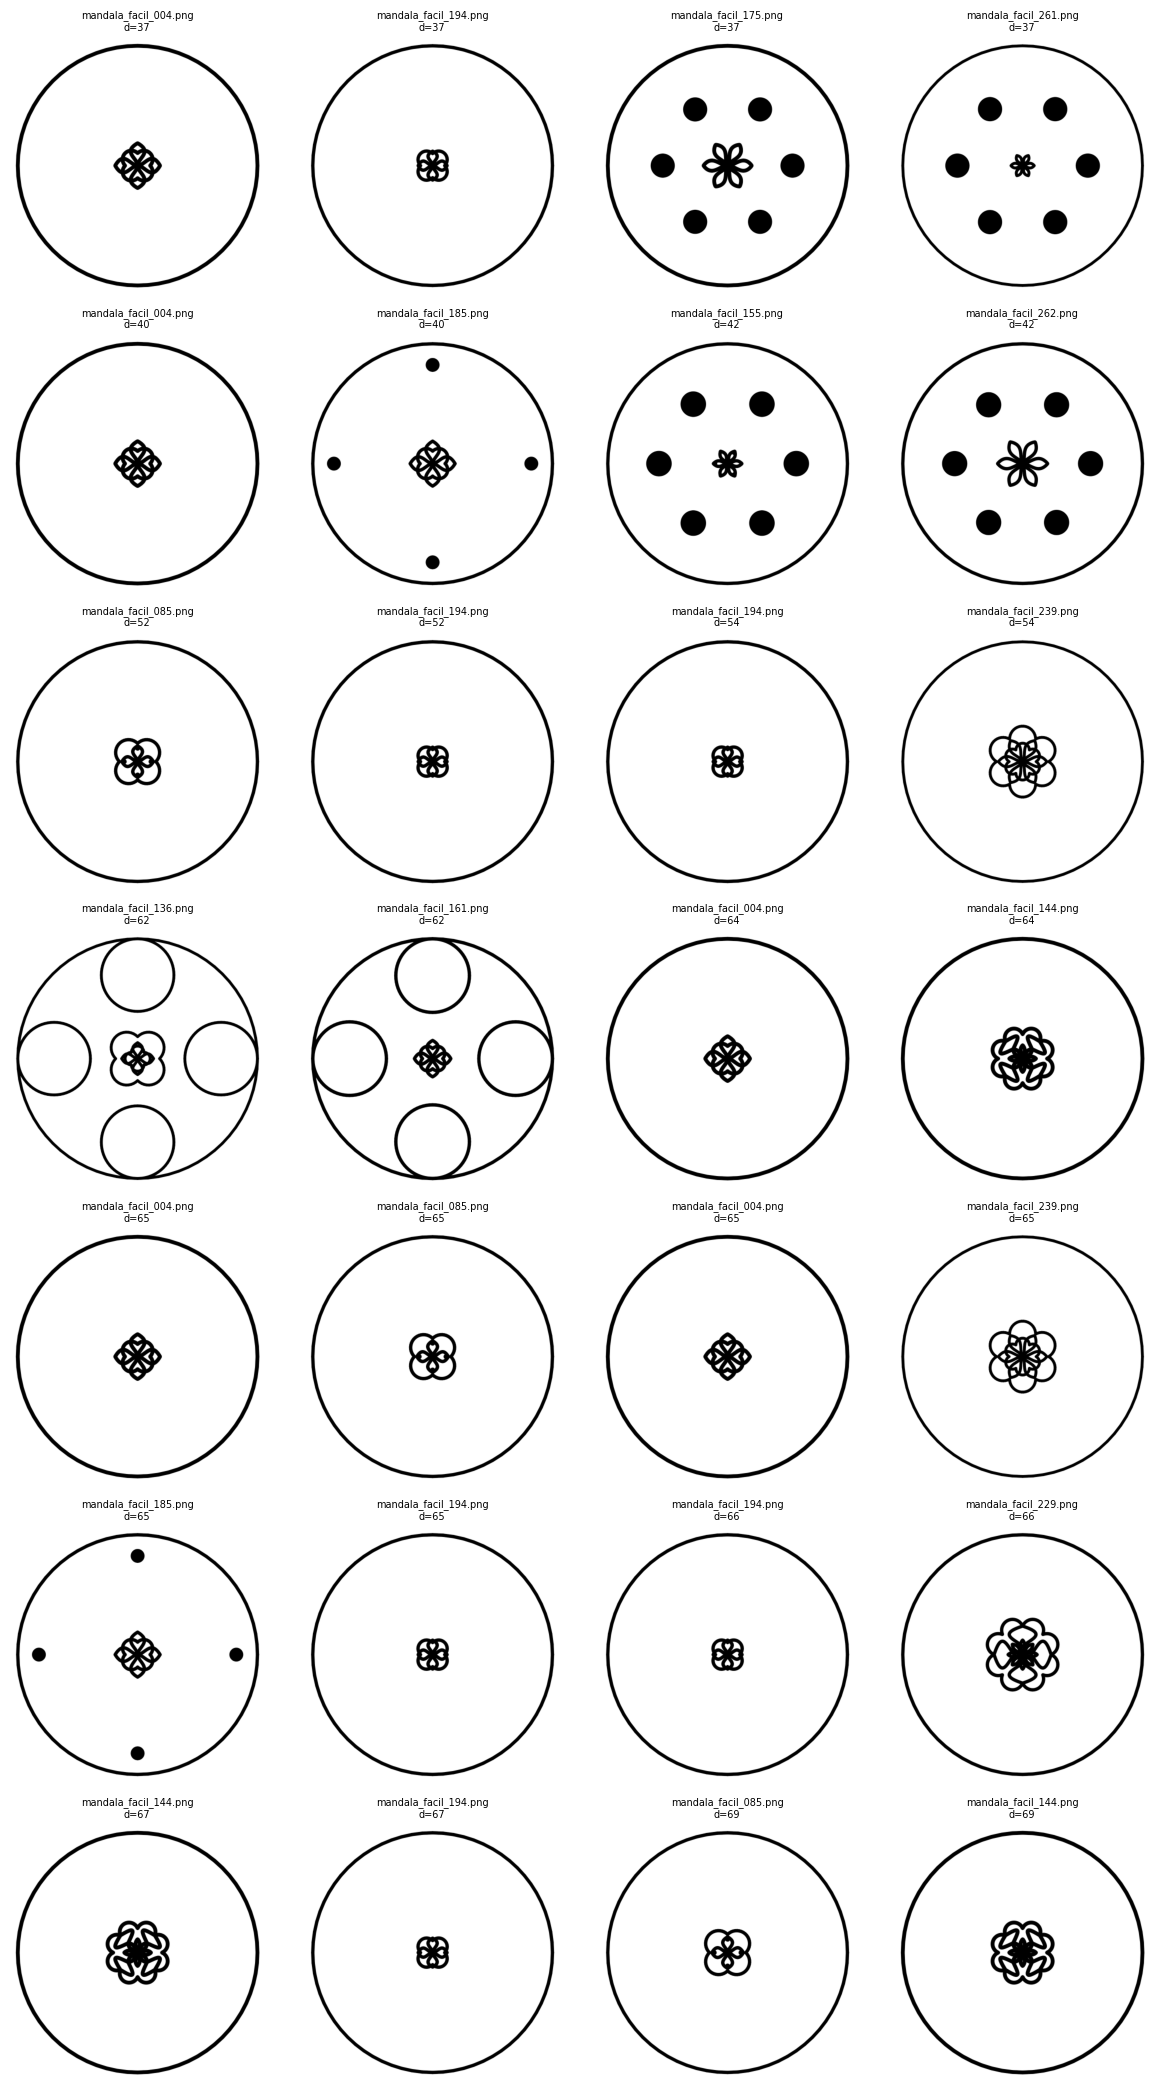

In [5]:
UMBRAL_HAMMING = 69   # incluye todo lo que aparece hasta el rango 65-69 del histograma
iu, ju = np.where(np.triu(dist <= UMBRAL_HAMMING, k=1))
pares = pd.DataFrame({'i': iu, 'j': ju, 'distancia': dist[iu, ju].astype(int)})
pares['ruta_a'] = df.loc[pares.i, 'ruta'].values
pares['ruta_b'] = df.loc[pares.j, 'ruta'].values
pares = pares.sort_values('distancia').reset_index(drop=True)

print(f"Pares con distancia ≤ {UMBRAL_HAMMING}: {len(pares)}")
print(pares[['ruta_a', 'ruta_b', 'distancia']].to_string())

# Cuadrícula: dos pares por fila (4 imágenes por fila)
filas = (len(pares) + 1) // 2
fig, ejes = plt.subplots(filas, 4, figsize=(12, 3 * filas))
ejes = np.atleast_2d(ejes)
for ax in ejes.ravel():
    ax.axis('off')
for k, r in pares.iterrows():
    fila, lado = divmod(k, 2)
    for c, ruta in enumerate((r.ruta_a, r.ruta_b)):
        ax = ejes[fila, lado * 2 + c]
        ax.imshow(Image.open(DATASET / ruta).convert('L'), cmap='gray')
        ax.set_title(f"{ruta.replace(chr(92), '/').split('/')[-1]}\nd={r.distancia}", fontsize=7)
plt.tight_layout()
plt.show()

In [6]:
SEMILLA = 42
FRACCIONES = {'train': 0.50, 'val': 0.15, 'test': 0.15, 'reto': 0.20}


padre = list(range(len(df)))
def raiz(x):
    while padre[x] != x:
        padre[x] = padre[padre[x]]
        x = padre[x]
    return x
for _, r in pares.iterrows():
    a, b = df.loc[r.i], df.loc[r.j]
    if (a.modalidad, a.nivel) == (b.modalidad, b.nivel):
        padre[raiz(r.i)] = raiz(r.j)
df['grupo'] = [raiz(i) for i in range(len(df))]


df['split'] = ''
for (mod, nivel), sub in df.groupby(['modalidad', 'nivel']):
    tamanos = sub.groupby('grupo').size().sample(frac=1, random_state=SEMILLA)
    tamanos = tamanos.sort_values(ascending=False, kind='stable')
    objetivo = {s: f * len(sub) for s, f in FRACCIONES.items()}
    asignado = {s: 0 for s in FRACCIONES}
    for g, tam in tamanos.items():
        s = max(FRACCIONES, key=lambda k: objetivo[k] - asignado[k])
        df.loc[sub.index[sub['grupo'] == g], 'split'] = s
        asignado[s] += tam

print(pd.crosstab([df.modalidad, df.nivel], df.split, margins=True))
print("\nGrupo más grande:", df.groupby('grupo').size().max(), "imágenes")

split                 reto  test  train  val   All
modalidad nivel                                   
mandalas  dificil       60    45    150   45   300
          facil         60    45    150   45   300
          intermedio    60    45    150   45   300
siluetas  dificil       20    15     50   15   100
          facil         20    15     50   15   100
          intermedio    20    15     50   15   100
All                    240   180    600  180  1200

Grupo más grande: 7 imágenes


In [7]:
mismo_estrato = pares[(df.loc[pares.i, ['modalidad', 'nivel']].values == df.loc[pares.j, ['modalidad', 'nivel']].values).all(1)]
fuga = (df.loc[mismo_estrato.i, 'split'].values != df.loc[mismo_estrato.j, 'split'].values).sum()
print(f'Pares casi duplicados del mismo estrato en conjuntos distintos: {fuga} (debe ser 0)')

entre = pares.drop(mismo_estrato.index)
aviso = (df.loc[entre.i, 'split'].values != df.loc[entre.j, 'split'].values).sum()
print(f'Pares casi duplicados entre niveles distintos y conjuntos distintos: {aviso} (revisar si es > 0)')

SOBRESCRIBIR = False
destino = DOCUMENTACION / 'division_dataset_v2.csv'
if destino.exists() and not SOBRESCRIBIR:
    print(f'\nYa existe {destino.name}; no se sobrescribe. Cambia SOBRESCRIBIR=True si lo autorizas.')
else:
    df.drop(columns='hash').assign(semilla=SEMILLA, umbral_hamming=UMBRAL_HAMMING, lado_hash=LADO_HASH).to_csv(destino, index=False)
    print(f'\nGuardado: {destino}')

Pares casi duplicados del mismo estrato en conjuntos distintos: 0 (debe ser 0)
Pares casi duplicados entre niveles distintos y conjuntos distintos: 0 (revisar si es > 0)

Ya existe division_dataset_v2.csv; no se sobrescribe. Cambia SOBRESCRIBIR=True si lo autorizas.


## 3. Preprocesamiento
Los módulos se escriben una sola vez (`procesamiento.py`, `comparador.py`) y se **reutilizan** aquí y en Streamlit, así no hay código duplicado.

Escala de grises → corrección de iluminación (para fotografías) → filtrado gaussiano → binarización mediante Otsu → eliminación de pequeñas regiones de ruido → recorte, escalado y centrado → extracción de trazos mediante esqueletización.

El mismo procedimiento de extracción de trazos se aplica inicialmente a mandalas y siluetas.

Qué problema resuelve cada paso con respecto a lo que hace una persona al dibujar:
- *Recorte + escala + centrado*: dibujo más grande, más pequeño o desplazado.
- *Esqueleto / borde*: trazos más gruesos o más finos.
- *Corrección de iluminación*: foto del dibujo con sombras.
- *Alineación fina* (sección 4): pequeñas inclinaciones.

In [8]:
%%writefile /content/tracelab_app/procesamiento.py
"""Preprocesamiento de imágenes de TraceLab."""
from pathlib import Path

import cv2
import numpy as np
from PIL import Image, ImageOps
from skimage.morphology import skeletonize

RAIZ = Path("/content/drive/MyDrive/Proyecto Final - Tracelab")
DATASET = RAIZ / "Dataset"
DOCUMENTACION = RAIZ / "documentacion"
RESULTADOS = RAIZ / "resultados"
CSV_DIVISION = DOCUMENTACION / "division_dataset_v2.csv"

MODALIDADES = ["mandalas", "siluetas"]
NIVELES = ["facil", "intermedio", "dificil"]
TIEMPOS = {"facil": 10, "intermedio": 15, "dificil": 20}
EXTENSIONES = {".jpg", ".jpeg", ".png"}

LADO = 256
CONTENIDO = 224
LADO_MAX_ENTRADA = 1600


def cargar_gris(fuente):
    """Lee una imagen (ruta o archivo subido) y la devuelve en escala de grises."""
    img = ImageOps.exif_transpose(Image.open(fuente))
    if img.mode in ("RGBA", "LA", "P"):
        img = img.convert("RGBA")
        fondo = Image.new("RGBA", img.size, (255, 255, 255, 255))
        fondo.alpha_composite(img)
        img = fondo
    return np.array(img.convert("L"))


def _quitar_fondo_desigual(gris):
    """Corrige sombras/iluminación despareja (útil en fotos de dibujos en papel)."""
    k = max(15, (min(gris.shape) // 8) | 1)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    fondo = cv2.morphologyEx(gris, cv2.MORPH_CLOSE, kernel)
    fondo = cv2.GaussianBlur(fondo, (0, 0), k / 3)
    return cv2.divide(gris, np.maximum(fondo, 1), scale=255)


def binarizar(gris, normalizar_fondo=False):
    """Devuelve una máscara uint8 con la tinta en 255 y el fondo en 0."""
    g = cv2.GaussianBlur(gris, (3, 3), 0)
    borde = np.concatenate([g[0, :], g[-1, :], g[:, 0], g[:, -1]])
    if np.median(borde) < 127:
        g = 255 - g
    if normalizar_fondo:
        g = _quitar_fondo_desigual(g)
    if g.std() < 3:
        return np.zeros_like(g)
    _, bw = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    _, etiquetas, stats, _ = cv2.connectedComponentsWithStats(bw, connectivity=8)
    area_min = max(6, int(0.00005 * bw.size))
    conservar = stats[:, cv2.CC_STAT_AREA] >= area_min
    conservar[0] = False
    return np.where(conservar[etiquetas], 255, 0).astype(np.uint8)


def encuadrar(mascara):
    """Recorta al contenido, lo escala y lo centra en un lienzo LADO x LADO.

    Así el desplazamiento y el tamaño del dibujo no penalizan la comparación.
    """
    lienzo = np.zeros((LADO, LADO), np.uint8)
    ys, xs = np.nonzero(mascara)
    if xs.size == 0:
        return lienzo, {"aspecto": 1.0, "tinta": 0.0, "tamano": 0.0}
    recorte = mascara[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    h, w = recorte.shape
    info = {
        "aspecto": w / h,
        "tinta": float((recorte > 0).mean()),
        "tamano": max(h, w) / max(mascara.shape),
    }
    f = CONTENIDO / max(h, w)
    nuevo = cv2.resize(recorte, (max(1, round(w * f)), max(1, round(h * f))),
                       interpolation=cv2.INTER_AREA)
    nuevo = np.where(nuevo > 40, 255, 0).astype(np.uint8)
    h2, w2 = nuevo.shape
    y0, x0 = (LADO - h2) // 2, (LADO - w2) // 2
    lienzo[y0:y0 + h2, x0:x0 + w2] = nuevo
    return lienzo, info

def extraer_trazos(mascara, modalidad=None):
    """Convierte la máscara en trazos de 1 píxel."""

    m = mascara > 0

    if not m.any():
        return m

    return skeletonize(m)


def preparar(fuente, modalidad, foto=False):
    """Pipeline completo. `fuente` puede ser ruta, archivo subido o arreglo gris.

    foto=True activa la corrección de iluminación (dibujos fotografiados).
    """
    gris = fuente if isinstance(fuente, np.ndarray) else cargar_gris(fuente)
    if max(gris.shape) > LADO_MAX_ENTRADA:
        f = LADO_MAX_ENTRADA / max(gris.shape)
        gris = cv2.resize(gris, None, fx=f, fy=f, interpolation=cv2.INTER_AREA)
    bw = binarizar(gris, normalizar_fondo=foto)
    mascara, info = encuadrar(bw)
    return {"gris": gris, "mascara": mascara,
            "trazos": extraer_trazos(mascara, modalidad), "info": info}

Writing /content/tracelab_app/procesamiento.py


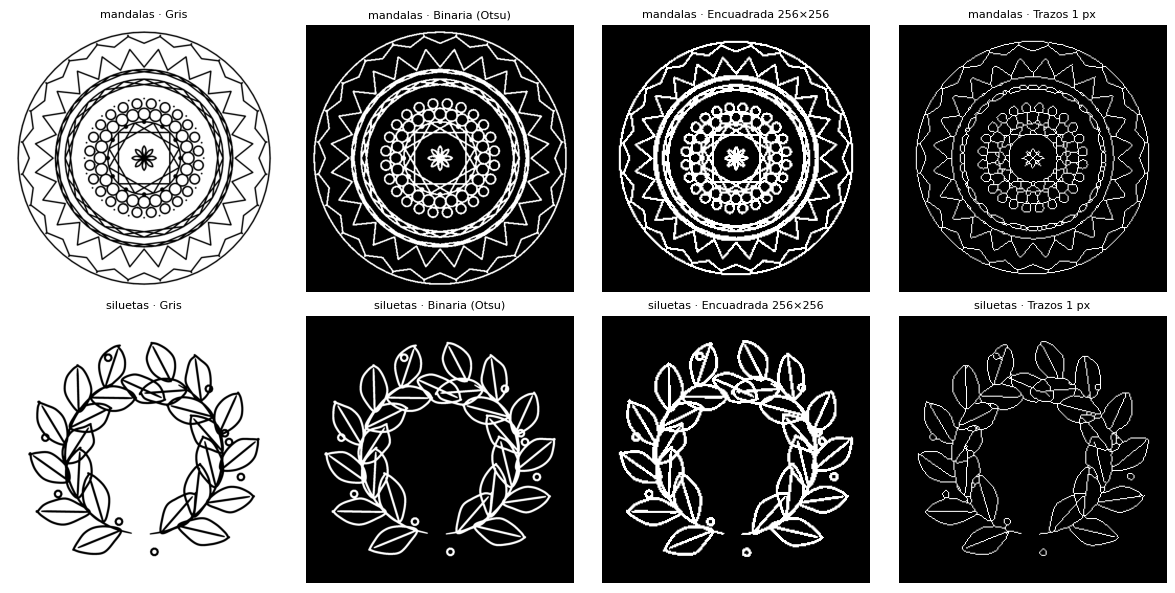

In [9]:
import sys, importlib
sys.path.insert(0, str(APP_LOCAL))
import procesamiento
importlib.reload(procesamiento)
from procesamiento import preparar, cargar_gris, binarizar, encuadrar

import matplotlib.pyplot as plt
muestra = df[df.split == 'train'].groupby('modalidad').sample(1, random_state=1)

fig, ejes = plt.subplots(len(muestra), 4, figsize=(12, 3 * len(muestra)))
for fila, (_, r) in zip(ejes, muestra.iterrows()):
    p = preparar(DATASET / r.ruta, r.modalidad)
    for ax, (im, titulo) in zip(fila, [(p['gris'], 'Gris'),
                                       (binarizar(p['gris']), 'Binaria (Otsu)'),
                                       (p['mascara'], 'Encuadrada 256×256'),
                                       (p['trazos'], 'Trazos 1 px')]):
        ax.imshow(im, cmap='gray'); ax.set_title(f'{r.modalidad} · {titulo}', fontsize=8); ax.axis('off')
plt.tight_layout(); plt.show()

## 4. Comparador de similitud
**Cómo se calcula el porcentaje** (todo sobre los trazos de 1 px, ya normalizados):

1. **Alineación fina:** se prueban pequeños giros (±4°), desplazamientos (±5 px) y escalas (±5 %) y se elige el ajuste que mejor encaja.
2. **F-score de trazos (50 %)**: *cobertura* = fracción de trazos del original que tienen un trazo tuyo a ≤ 4 px; *precisión* = fracción de tus trazos que tienen un trazo del original a ≤ 4 px; el F-score es su media armónica.
3. **Chamfer (30 %)**: distancia media entre los trazos de ambas imágenes en los dos sentidos, convertida a puntaje con `exp(-d/8)`.
4. **Estructura SSIM (20 %)**: SSIM entre versiones suavizadas de los trazos (captura la organización global, no el píxel exacto).

Los pesos y la tolerancia son **valores iniciales**; se ajustan con *val* y se reportan sobre *test*.

El porcentaje **no** mide memoria, inteligencia ni calidad artística: solo similitud visual de trazos y estructura.

In [10]:
%%writefile /content/tracelab_app/comparador.py
"""Comparador de similitud visual de TraceLab (procesamiento clásico, sin entrenamiento)."""
from itertools import product

import cv2
import numpy as np
from skimage.metrics import structural_similarity

from procesamiento import LADO, preparar

TOLERANCIA = 4
ESCALA_CHAMFER = 8.0
PESOS = {"trazos": 0.5, "chamfer": 0.3, "estructura": 0.2}
ANGULOS = (-4, 0, 4)
DESPLAZAMIENTOS = (-5, 0, 5)
ESCALAS = (0.95, 1.0, 1.05)


def _distancia(trazos):
    """Mapa con la distancia de cada píxel al trazo más cercano."""
    if not trazos.any():
        return np.full(trazos.shape, 1e3, np.float32)
    return cv2.distanceTransform((~trazos).astype(np.uint8), cv2.DIST_L2, 3)


def _transformar(trazos, angulo, dx, dy, escala):
    c = LADO / 2
    M = cv2.getRotationMatrix2D((c, c), angulo, escala)
    M[:, 2] += (dx, dy)
    sal = cv2.warpAffine(trazos.astype(np.uint8), M, (LADO, LADO), flags=cv2.INTER_NEAREST)
    return sal > 0


def _f_trazos(ref, dib, d_ref):
    d_dib = _distancia(dib)
    p = float((d_ref[dib] <= TOLERANCIA).mean())
    c = float((d_dib[ref] <= TOLERANCIA).mean())
    return 2 * p * c / (p + c + 1e-9)


def alinear(ref, dib):
    """Busca el ajuste fino (giro, desplazamiento, escala pequeños) que mejor
    encaja el dibujo con la referencia. Parte de la identidad para que, en empate,
    no se mueva nada."""
    if not ref.any() or not dib.any():
        return dib
    d_ref = _distancia(ref)
    mejor, mejor_f = dib, _f_trazos(ref, dib, d_ref)
    for a, dx, dy, s in product(ANGULOS, DESPLAZAMIENTOS, DESPLAZAMIENTOS, ESCALAS):
        if (a, dx, dy, s) == (0, 0, 0, 1.0):
            continue
        cand = _transformar(dib, a, dx, dy, s)
        if not cand.any():
            continue
        f = _f_trazos(ref, cand, d_ref)
        if f > mejor_f + 1e-9:
            mejor, mejor_f = cand, f
    return mejor


def calcular_metricas(ref, dib):
    if not ref.any() or not dib.any():
        return {"precision": 0.0, "cobertura": 0.0, "f_trazos": 0.0,
                "chamfer_px": float(LADO), "estructura": 0.0}
    d_ref, d_dib = _distancia(ref), _distancia(dib)
    precision = float((d_ref[dib] <= TOLERANCIA).mean())
    cobertura = float((d_dib[ref] <= TOLERANCIA).mean())
    f = 2 * precision * cobertura / (precision + cobertura + 1e-9)
    chamfer = 0.5 * (float(d_ref[dib].mean()) + float(d_dib[ref].mean()))
    a = cv2.GaussianBlur(ref.astype(np.float32), (0, 0), 3)
    b = cv2.GaussianBlur(dib.astype(np.float32), (0, 0), 3)
    a /= max(float(a.max()), 1e-9)
    b /= max(float(b.max()), 1e-9)
    estructura = float(np.clip(structural_similarity(a, b, data_range=1.0, win_size=11), 0, 1))
    return {"precision": precision, "cobertura": cobertura, "f_trazos": f,
            "chamfer_px": chamfer, "estructura": estructura}


def puntaje(m):
    sub = {"trazos": m["f_trazos"],
           "chamfer": float(np.exp(-m["chamfer_px"] / ESCALA_CHAMFER)),
           "estructura": m["estructura"]}
    return 100 * sum(PESOS[k] * sub[k] for k in PESOS), sub


def categoria(p):
    if p >= 85: return "muy alta"
    if p >= 70: return "alta"
    if p >= 50: return "media"
    if p >= 30: return "baja"
    return "muy baja"


def explicar(m, info_ref, info_dib, p):
    t = [f"Similitud {categoria(p)} ({p:.0f} %).",
         f"Cobertura: {m['cobertura']*100:.0f} % de los trazos del original aparecen en tu dibujo "
         f"(tolerancia de ±{TOLERANCIA} px sobre un lienzo de {LADO} px).",
         f"Precisión: {m['precision']*100:.0f} % de tus trazos coincide con el original; "
         f"el resto son trazos que no están en la imagen."]
    r = info_dib["aspecto"] / max(info_ref["aspecto"], 1e-9)
    if abs(r - 1) > 0.15:
        t.append("Proporciones: tu dibujo es " + ("más ancho" if r > 1 else "más alto")
                 + " de lo que es el original.")
    else:
        t.append("Proporciones: el ancho y el alto generales son parecidos a los del original.")
    q = info_dib["tinta"] / max(info_ref["tinta"], 1e-9)
    if q > 1.8:
        t.append("Trazo: tu dibujo tiene bastante más tinta (trazos más gruesos o más elementos).")
    elif q < 0.55:
        t.append("Trazo: tu dibujo tiene bastante menos tinta (trazos más finos o menos elementos).")
    if m["cobertura"] < 0.5 and m["precision"] >= 0.6:
        t.append("Te faltaron partes del original, pero lo que dibujaste sí corresponde.")
    elif m["precision"] < 0.5 and m["cobertura"] >= 0.6:
        t.append("Reprodujiste gran parte del original, pero añadiste varios trazos que no estaban.")
    t.append("El porcentaje mide similitud visual de trazos y estructura tras normalizar posición y "
             "tamaño. No es una medida de memoria, inteligencia ni calidad artística.")
    return t


def comparar_preparadas(ref, dib):
    trazos_dib = alinear(ref["trazos"], dib["trazos"])
    m = calcular_metricas(ref["trazos"], trazos_dib)
    p, sub = puntaje(m)
    return {"puntaje": p, "subpuntajes": sub, "metricas": m,
            "trazos_ref": ref["trazos"], "trazos_dib": trazos_dib,
            "gris_ref": ref["gris"], "gris_dib": dib["gris"],
            "explicacion": explicar(m, ref["info"], dib["info"], p)}


def comparar(fuente_ref, fuente_dib, modalidad, foto=True):
    """Compara original y dibujo. foto=True para dibujos subidos por el usuario."""
    ref = preparar(fuente_ref, modalidad, foto=False)
    dib = preparar(fuente_dib, modalidad, foto=foto)
    if not dib["trazos"].any():
        raise ValueError("No se detectaron trazos en el dibujo. Revisa el contraste y la imagen.")
    return comparar_preparadas(ref, dib)


def superposicion(res):
    """Imagen RGB: verde = coincide, rojo = falta en tu dibujo, azul = sobra."""
    ref, dib = res["trazos_ref"], res["trazos_dib"]
    d_ref, d_dib = _distancia(ref), _distancia(dib)
    ok_ref = ref & (d_dib <= TOLERANCIA)
    ok_dib = dib & (d_ref <= TOLERANCIA)
    img = np.full((LADO, LADO, 3), 255, np.uint8)
    k = np.ones((3, 3), np.uint8)

    def pintar(mascara, color):
        img[cv2.dilate(mascara.astype(np.uint8), k) > 0] = color

    pintar(ref & ~ok_ref, (214, 39, 40))
    pintar(dib & ~ok_dib, (31, 119, 180))
    pintar(ok_ref | ok_dib, (44, 160, 44))
    return img

Writing /content/tracelab_app/comparador.py


In [11]:
import sys
import importlib
from pathlib import Path

sys.path.insert(0, '/content/tracelab_app')

print("Archivos encontrados:")

for archivo in ['procesamiento.py', 'comparador.py']:
    ruta = Path('/content/tracelab_app') / archivo
    print(archivo, "OK" if ruta.exists() else "NO ENCONTRADO")

importlib.invalidate_caches()

import comparador

print("\n¡Comparador importado correctamente!")

Archivos encontrados:
procesamiento.py OK
comparador.py OK

¡Comparador importado correctamente!


Misma imagen:  100.0 %   (esperado ≈ 100)
Imagen distinta: 50.8 %   (esperado claramente menor)


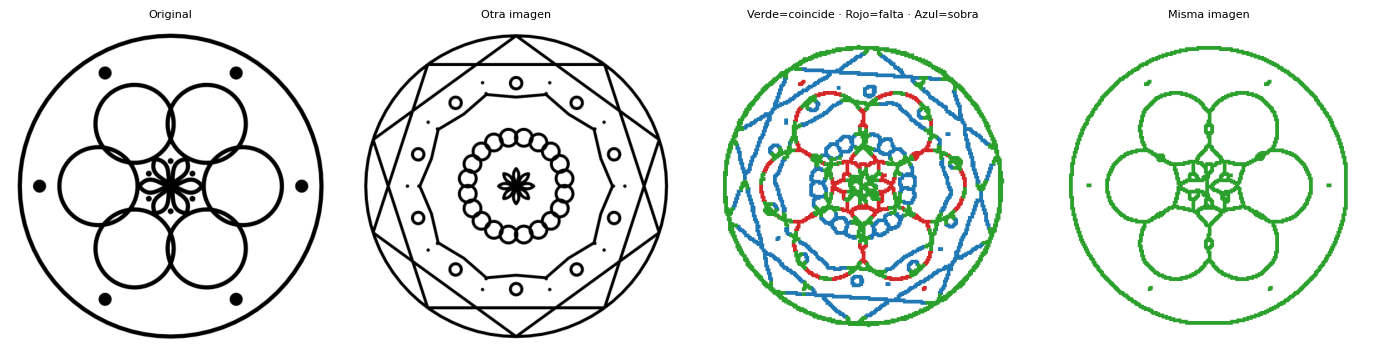

In [12]:
# Celda 4.2 — Verificación básica: una imagen contra sí misma y contra otra distinta
import comparador
importlib.reload(comparador)
from comparador import comparar, superposicion

mod = 'mandalas'
imgs = df[(df.split == 'val') & (df.modalidad == mod)].sample(2, random_state=3)
ref_ruta, otra_ruta = (DATASET / r for r in imgs.ruta)

misma = comparar(ref_ruta, ref_ruta, mod, foto=False)
otra = comparar(ref_ruta, otra_ruta, mod, foto=False)
print(f"Misma imagen:  {misma['puntaje']:.1f} %   (esperado ≈ 100)")
print(f"Imagen distinta: {otra['puntaje']:.1f} %   (esperado claramente menor)")

fig, ejes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, (im, t, cm) in zip(ejes, [(otra['gris_ref'], 'Original', 'gray'),
                                  (otra['gris_dib'], 'Otra imagen', 'gray'),
                                  (superposicion(otra), 'Verde=coincide · Rojo=falta · Azul=sobra', None),
                                  (superposicion(misma), 'Misma imagen', None)]):
    ax.imshow(im, cmap=cm); ax.set_title(t, fontsize=8); ax.axis('off')
plt.tight_layout(); plt.show()

## 5. Validación con reproducciones sintéticas
**Aviso metodológico:** estas reproducciones son **simuladas** (desplazar, escalar, rotar, engrosar, ruido, temblor, borrar partes). Sirven para comprobar que el comparador es **robusto** a los cambios que una persona podría introducir y que **distingue** una imagen distinta. **No** sustituyen a dibujos humanos reales y no se deben presentar como tales.

Se usa solo el conjunto **val**. Los resultados se calculan aquí; no hay cifras precalculadas.

In [13]:
# Celda 5.1 — Generador de reproducciones sintéticas (todas etiquetadas como sintéticas)
import cv2

def _fondo(g):
    return int(np.median(np.concatenate([g[0], g[-1], g[:, 0], g[:, -1]])))

def perturbar(g, tipo, rng):
    h, w = g.shape
    fondo = _fondo(g)
    if tipo == 'identica':
        return g.copy()
    if tipo == 'desplazado':
        dx, dy = rng.uniform(-0.05, 0.05, 2) * (w, h)
        return cv2.warpAffine(g, np.float32([[1, 0, dx], [0, 1, dy]]), (w, h), borderValue=fondo)
    if tipo in ('escalado_pequeno', 'escalado_grande'):
        s = 0.6 if tipo == 'escalado_pequeno' else 1.2
        return cv2.warpAffine(g, cv2.getRotationMatrix2D((w / 2, h / 2), 0, s), (w, h), borderValue=fondo)
    if tipo == 'rotado':
        a = rng.uniform(-6, 6)
        return cv2.warpAffine(g, cv2.getRotationMatrix2D((w / 2, h / 2), a, 1), (w, h), borderValue=fondo)
    if tipo == 'trazo_grueso':
        k = np.ones((max(3, (w // 200) * 2 + 1),) * 2, np.uint8)
        return cv2.erode(g, k) if fondo > 127 else cv2.dilate(g, k)
    if tipo == 'ruido':
        ruido = g + rng.normal(0, 25, g.shape)
        return np.clip(ruido, 0, 255).astype(np.uint8)
    if tipo == 'trazos_omitidos':
        out = g.copy()
        for _ in range(3):
            x, y = rng.integers(0, int(w * 0.8)), rng.integers(0, int(h * 0.8))
            out[y:y + int(h * 0.18), x:x + int(w * 0.18)] = fondo
        return out
    if tipo == 'temblor':
        yy, xx = np.mgrid[0:h, 0:w].astype(np.float32)
        def campo():
            q = cv2.GaussianBlur(rng.normal(0, 1, (h, w)).astype(np.float32), (0, 0), w / 15)
            return q / (q.std() + 1e-9) * 0.015 * w
        return cv2.remap(g, xx + campo(), yy + campo(), cv2.INTER_LINEAR, borderValue=fondo)
    if tipo == 'combinado':
        for t in ('desplazado', 'escalado_pequeno', 'temblor', 'trazo_grueso'):
            g = perturbar(g, t, rng)
        return g
    raise ValueError(tipo)

TIPOS = ['identica', 'desplazado', 'escalado_pequeno', 'escalado_grande', 'rotado',
         'trazo_grueso', 'ruido', 'trazos_omitidos', 'temblor', 'combinado']
print('Tipos de perturbación:', TIPOS, '+ otra_imagen (control negativo)')

Tipos de perturbación: ['identica', 'desplazado', 'escalado_pequeno', 'escalado_grande', 'rotado', 'trazo_grueso', 'ruido', 'trazos_omitidos', 'temblor', 'combinado'] + otra_imagen (control negativo)


In [14]:

# ============================================================
# TraceLab - Celda 5.2
# Evaluación del comparador con imágenes de validación
# ============================================================

import procesamiento
import comparador
import numpy as np
import pandas as pd

N_POR_ESTRATO = 15

rng = np.random.default_rng(SEMILLA)
resultados = []

val = df[df.split == 'val']

for (mod, nivel), sub in val.groupby(['modalidad', 'nivel']):

    muestra = sub.sample(
        min(N_POR_ESTRATO, len(sub)),
        random_state=SEMILLA
    )

    rutas = list(muestra.ruta)

    for k, ruta in enumerate(rutas):


        g = procesamiento.cargar_gris(DATASET / ruta)


        ref = procesamiento.preparar(g, mod, foto=False)


        for tipo in TIPOS:

            dib = procesamiento.preparar(
                perturbar(g, tipo, rng),
                mod,
                foto=False
            )

            r = comparador.comparar_preparadas(ref, dib)

            resultados.append({
                'modalidad': mod,
                'nivel': nivel,
                'ruta': ruta,
                'tipo': tipo,
                'puntaje': r['puntaje'],
                **r['metricas']
            })


        otra = procesamiento.cargar_gris(
            DATASET / rutas[(k + 1) % len(rutas)]
        )

        r = comparador.comparar_preparadas(
            ref,
            procesamiento.preparar(otra, mod, foto=False)
        )

        resultados.append({
            'modalidad': mod,
            'nivel': nivel,
            'ruta': ruta,
            'tipo': 'otra_imagen',
            'puntaje': r['puntaje'],
            **r['metricas']
        })


res = pd.DataFrame(resultados)

res['sintetico'] = True

RESULTADOS.mkdir(exist_ok=True)

res.to_csv(
    RESULTADOS / 'pruebas_sinteticas_val.csv',
    index=False
)

resumen = res.pivot_table(
    index='tipo',
    columns='modalidad',
    values='puntaje',
    aggfunc=['mean', 'std', 'min']
).round(1)

print("Evaluación completada.")
display(resumen)


Evaluación completada.


mean               std               min         
modalidad        mandalas siluetas mandalas siluetas mandalas siluetas
tipo                                                                  
combinado            66.8     68.9      5.7      6.6     48.4     46.3
desplazado           95.0     99.6      4.0      0.4     81.6     98.2
escalado_grande      61.3     93.7     10.1      1.5     43.5     89.4
escalado_pequeno     97.7     99.3      1.5      0.5     90.1     97.6
identica            100.0    100.0      0.0      0.0    100.0    100.0
otra_imagen          58.6     36.2      9.3     12.5     33.4     15.5
rotado               96.7     93.5      1.6      3.6     92.9     80.5
ruido                99.4     99.8      0.6      0.3     97.8     98.7
temblor              77.9     79.0      3.4      5.1     70.8     68.8
trazo_grueso         92.9     93.9      4.3      2.9     75.0     85.5
trazos_omitidos      93.9     92.3      2.5      7.5     85.1     51.7

In [15]:
print("Tipos de pruebas disponibles:")
print(sorted(res['tipo'].unique()))

print("\nCantidad de pruebas por tipo:")
display(res.groupby(['modalidad', 'tipo']).size().unstack())

Tipos de pruebas disponibles:
['combinado', 'desplazado', 'escalado_grande', 'escalado_pequeno', 'identica', 'otra_imagen', 'rotado', 'ruido', 'temblor', 'trazo_grueso', 'trazos_omitidos']

Cantidad de pruebas por tipo:


tipo,combinado,desplazado,escalado_grande,escalado_pequeno,identica,otra_imagen,rotado,ruido,temblor,trazo_grueso,trazos_omitidos
modalidad,,,,,,,,,,,
mandalas,45,45,45,45,45,45,45,45,45,45,45
siluetas,45,45,45,45,45,45,45,45,45,45,45


In [16]:
# Celda 5.3 — ¿El comparador separa "misma imagen alterada" de "imagen distinta"?

filas = []
for (mod, nivel), g in res.groupby(['modalidad', 'nivel']):
    umbral = g.loc[g.tipo == 'otra_imagen', 'puntaje'].quantile(0.95)
    for tipo, gt in g[g.tipo != 'otra_imagen'].groupby('tipo'):
        filas.append({'modalidad': mod, 'nivel': nivel, 'tipo': tipo,
                      'umbral_otra_imagen': umbral, 'pct_por_encima': (gt.puntaje > umbral).mean() * 100})
sep = pd.DataFrame(filas)
print('% de reproducciones alteradas que obtienen más puntaje que el p95 de una imagen distinta:')
sep.pivot_table(index='tipo', columns=['modalidad', 'nivel'], values='pct_por_encima').round(0)

% de reproducciones alteradas que obtienen más puntaje que el p95 de una imagen distinta:


modalidad        mandalas                   siluetas                  
nivel             dificil  facil intermedio  dificil  facil intermedio
tipo                                                                  
combinado             7.0   93.0       20.0     80.0  100.0      100.0
desplazado          100.0  100.0      100.0    100.0  100.0      100.0
escalado_grande       7.0   27.0       13.0    100.0  100.0      100.0
escalado_pequeno    100.0  100.0      100.0    100.0  100.0      100.0
identica            100.0  100.0      100.0    100.0  100.0      100.0
rotado              100.0  100.0      100.0    100.0  100.0      100.0
ruido               100.0  100.0      100.0    100.0  100.0      100.0
temblor             100.0  100.0      100.0    100.0  100.0      100.0
trazo_grueso         93.0  100.0      100.0    100.0  100.0      100.0
trazos_omitidos     100.0  100.0      100.0    100.0  100.0      100.0

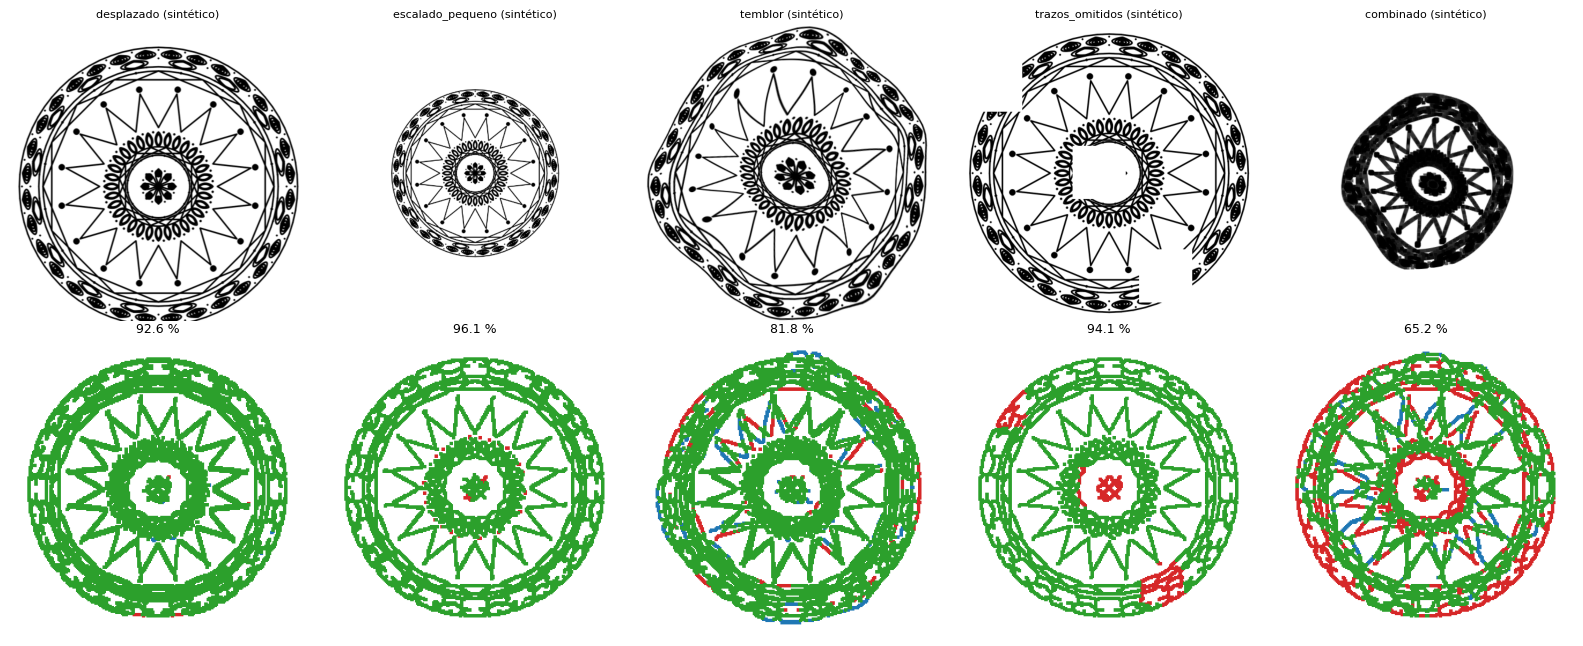

In [17]:

# ============================================================
# TraceLab - Celda 5.4
# Ejemplos visuales de las modificaciones sintéticas
# ============================================================

import procesamiento
import comparador
import numpy as np
import matplotlib.pyplot as plt


ej = val[val.modalidad == 'mandalas'].sample(
    1, random_state=7
).iloc[0]


g = procesamiento.cargar_gris(DATASET / ej.ruta)
ref = procesamiento.preparar(g, 'mandalas', foto=False)


tipos_ej = [
    'desplazado',
    'escalado_pequeno',
    'temblor',
    'trazos_omitidos',
    'combinado'
]

fig, ejes = plt.subplots(
    2, len(tipos_ej),
    figsize=(3.2 * len(tipos_ej), 6.5)
)

for col, tipo in enumerate(tipos_ej):

    sint = perturbar(
        g, tipo, np.random.default_rng(1)
    )

    dib = procesamiento.preparar(
        sint, 'mandalas', foto=False
    )

    r = comparador.comparar_preparadas(ref, dib)

    ejes[0, col].imshow(sint, cmap='gray')
    ejes[0, col].set_title(
        f'{tipo} (sintético)', fontsize=8
    )


    ejes[1, col].imshow(
        comparador.superposicion(r)
    )
    ejes[1, col].set_title(
        f"{r['puntaje']:.1f} %", fontsize=9
    )

    ejes[0, col].axis('off')
    ejes[1, col].axis('off')

plt.tight_layout()
plt.show()


In [18]:
# Celda 5.5 — Separación: imágenes distintas vs. alteraciones leves (solo lectura)
neg = res[res.tipo == 'otra_imagen']
print("Puntaje de imágenes DISTINTAS:")
print(neg.groupby(['modalidad', 'nivel']).puntaje.describe()[['count', 'mean', 'min', '50%', 'max']].round(1))

leves = res[res.tipo.isin(['desplazado', 'ruido', 'trazo_grueso', 'rotado', 'escalado_pequeno'])]
t = pd.DataFrame({'otra_max': neg.groupby(['modalidad', 'nivel']).puntaje.max(),
                  'leves_min': leves.groupby(['modalidad', 'nivel']).puntaje.min()}).round(1)
t['margen'] = (t.leves_min - t.otra_max).round(1)
print("\nMargen (positivo = separación completa):")
print(t)

Puntaje de imágenes DISTINTAS:
                      count  mean   min   50%   max
modalidad nivel                                    
mandalas  dificil      15.0  65.0  45.6  66.9  75.5
          facil        15.0  54.5  50.9  55.1  57.5
          intermedio   15.0  56.4  33.4  56.1  72.6
siluetas  dificil      15.0  49.5  33.1  51.4  68.2
          facil        15.0  27.3  15.5  27.0  36.8
          intermedio   15.0  31.9  23.3  30.2  45.1

Margen (positivo = separación completa):
                      otra_max  leves_min  margen
modalidad nivel                                  
mandalas  dificil         75.5       75.0    -0.5
          facil           57.5       88.9    31.4
          intermedio      72.6       81.6     9.0
siluetas  dificil         68.2       85.5    17.3
          facil           36.8       88.9    52.1
          intermedio      45.1       80.5    35.4


In [19]:
tol_original = comparador.TOLERANCIA

mand = df[(df.split == 'val') & (df.modalidad == 'mandalas')]
rng_t = np.random.default_rng(SEMILLA)
TIPOS_T = ['desplazado', 'trazo_grueso', 'rotado']


prep = {}
for nivel, sub in mand.groupby('nivel'):
    rutas = list(sub.ruta)
    for k, ruta in enumerate(rutas):
        g = procesamiento.cargar_gris(DATASET / ruta)
        otra_g = procesamiento.cargar_gris(DATASET / rutas[(k + 1) % len(rutas)])
        prep[(nivel, ruta)] = {
            'ref': procesamiento.preparar(g, 'mandalas'),
            'otra': procesamiento.preparar(otra_g, 'mandalas'),
            **{t: procesamiento.preparar(perturbar(g, t, rng_t), 'mandalas') for t in TIPOS_T}}

filas = []
for tol in [2, 3, 4]:
    comparador.TOLERANCIA = tol
    for (nivel, ruta), d in prep.items():
        for clave in ['otra'] + TIPOS_T:
            r = comparador.comparar_preparadas(d['ref'], d[clave])
            filas.append({'tol': tol, 'nivel': nivel,
                          'tipo': 'otra_imagen' if clave == 'otra' else clave,
                          'puntaje': r['puntaje']})
comparador.TOLERANCIA = tol_original

e = pd.DataFrame(filas)
neg = e[e.tipo == 'otra_imagen'].groupby(['tol', 'nivel']).puntaje.max()
lev = e[e.tipo != 'otra_imagen'].groupby(['tol', 'nivel']).puntaje.min()
print(pd.DataFrame({'otra_max': neg, 'leves_min': lev, 'margen': lev - neg}).round(1))

                otra_max  leves_min  margen
tol nivel                                  
2   dificil         72.7       72.6    -0.1
    facil           61.0       61.0    -0.0
    intermedio      81.9       68.7   -13.2
3   dificil         79.9       78.3    -1.6
    facil           63.4       68.5     5.1
    intermedio      84.4       78.9    -5.5
4   dificil         82.0       75.0    -7.0
    facil           65.1       76.9    11.8
    intermedio      85.6       83.5    -2.2


In [20]:
filas = []
for (tol, nivel), g in e.groupby(['tol', 'nivel']):
    pos = g[g.tipo != 'otra_imagen'].puntaje.values
    neg = g[g.tipo == 'otra_imagen'].puntaje.values
    auc = (pos[:, None] > neg[None, :]).mean() + 0.5 * (pos[:, None] == neg[None, :]).mean()
    filas.append({'tol': tol, 'nivel': nivel, 'AUC': auc,
                  'leves_p5': np.percentile(pos, 5), 'otra_p95': np.percentile(neg, 95),
                  'n_leves': len(pos), 'n_otra': len(neg)})
print(pd.DataFrame(filas).round(3).to_string(index=False))

 tol      nivel   AUC  leves_p5  otra_p95  n_leves  n_otra
   2    dificil 1.000    79.255    66.344      135      45
   2      facil 1.000    77.197    55.173      135      45
   2 intermedio 0.999    81.500    62.096      135      45
   3    dificil 1.000    85.069    73.662      135      45
   3      facil 1.000    87.436    58.580      135      45
   3 intermedio 1.000    89.373    66.677      135      45
   4    dificil 0.998    86.589    77.221      135      45
   4      facil 1.000    88.492    60.971      135      45
   4 intermedio 1.000    89.732    70.420      135      45


## Evaluación final independiente con test.

In [21]:
import numpy as np
import pandas as pd
import procesamiento
import comparador

N_POR_ESTRATO_TEST = 15

rng_test = np.random.default_rng(123)
resultados_test = []


test = df[df['split'] == 'test']

for (mod, nivel), sub in test.groupby(['modalidad', 'nivel']):

    muestra = sub.sample(
        min(N_POR_ESTRATO_TEST, len(sub)),
        random_state=123
    )

    rutas = list(muestra.ruta)

    for k, ruta in enumerate(rutas):


        gris = procesamiento.cargar_gris(DATASET / ruta)
        ref = procesamiento.preparar(gris, mod, foto=False)


        for tipo in TIPOS:

            sintetica = perturbar(gris, tipo, rng_test)

            dib = procesamiento.preparar(
                sintetica, mod, foto=False
            )

            r = comparador.comparar_preparadas(ref, dib)

            resultados_test.append({
                'modalidad': mod,
                'nivel': nivel,
                'tipo': tipo,
                'ruta': ruta,
                'puntaje': r['puntaje']
            })


        otra_ruta = rutas[(k + 1) % len(rutas)]

        otra = procesamiento.cargar_gris(
            DATASET / otra_ruta
        )

        dib_otra = procesamiento.preparar(
            otra, mod, foto=False
        )

        r = comparador.comparar_preparadas(ref, dib_otra)

        resultados_test.append({
            'modalidad': mod,
            'nivel': nivel,
            'tipo': 'otra_imagen',
            'ruta': ruta,
            'puntaje': r['puntaje']
        })


res_test = pd.DataFrame(resultados_test)

res_test['sintetico'] = True

RESULTADOS.mkdir(parents=True, exist_ok=True)

res_test.to_csv(
    RESULTADOS / 'pruebas_sinteticas_test.csv',
    index=False
)


resumen_test = res_test.pivot_table(
    index=['modalidad', 'nivel', 'tipo'],
    values='puntaje',
    aggfunc=['mean', 'std', 'min', 'max']
).round(2)

print("Evaluación final del conjunto TEST")
display(resumen_test)


Evaluación final del conjunto TEST


mean     std     min     max
                                      puntaje puntaje puntaje puntaje
modalidad nivel      tipo                                            
mandalas  dificil    combinado          70.86    4.73   61.34   77.03
                     desplazado         94.73    3.30   89.19   99.58
                     escalado_grande    69.43    5.14   56.69   76.39
                     escalado_pequeno   97.14    1.24   94.37   98.54
                     identica          100.00    0.00  100.00  100.00
...                                       ...     ...     ...     ...
siluetas  intermedio rotado             94.74    2.37   91.47   99.83
                     ruido              99.91    0.08   99.72   99.98
                     temblor            76.82    4.97   63.88   84.52
                     trazo_grueso       94.48    2.17   89.89   97.66
                     trazos_omitidos    90.23    7.45   65.45   96.40

[66 rows x 4 columns]

## Calcular el AUC del conjunto TEST

In [22]:
filas_auc = []

for (mod, nivel), grupo in res_test.groupby(
    ['modalidad', 'nivel']
):

    positivos = grupo[
        grupo.tipo != 'otra_imagen'
    ]['puntaje'].values

    negativos = grupo[
        grupo.tipo == 'otra_imagen'
    ]['puntaje'].values

    if len(positivos) == 0 or len(negativos) == 0:
        continue

    auc = (
        (positivos[:, None] > negativos[None, :]).mean()
        + 0.5 * (
            positivos[:, None] == negativos[None, :]
        ).mean()
    )

    filas_auc.append({
        'modalidad': mod,
        'nivel': nivel,
        'AUC': auc,
        'promedio_positivos': positivos.mean(),
        'promedio_negativos': negativos.mean(),
        'cantidad_positivos': len(positivos),
        'cantidad_negativos': len(negativos)
    })

tabla_auc = pd.DataFrame(filas_auc)

print("Resultados AUC del conjunto TEST")
display(tabla_auc.round(3))


Resultados AUC del conjunto TEST


,modalidad,nivel,AUC,promedio_positivos,promedio_negativos,cantidad_positivos,cantidad_negativos
0,mandalas,dificil,0.906,89.327,70.117,150,15
1,mandalas,facil,0.936,87.083,51.072,150,15
2,mandalas,intermedio,0.937,88.235,58.747,150,15
3,siluetas,dificil,0.994,91.994,48.429,150,15
4,siluetas,facil,1.000,92.052,29.953,150,15
5,siluetas,intermedio,1.000,91.469,33.932,150,15


## 6. Dibujos humanos reales (cuando se recolecten)
Esta es la evaluación que realmente sustenta el proyecto.

**Convención de nombres** en `Dataset/dibujos_usuarios/<modalidad>/`:
`<nombre_del_original_sin_extensión>__<participante>.png`  (por ejemplo `mandala_0123__p01.jpg`).

**Validación recomendada:** 2–3 personas valoran cada dibujo de 1 a 5 (sin ver el puntaje) y se calcula la correlación de Spearman con el puntaje del comparador. Guarda las valoraciones en `documentacion/valoraciones_humanas.csv` con columnas `archivo,valoracion` (una fila por valoración).

In [23]:
# Celda 6.1 — Evaluar los dibujos reales que existan (si la carpeta está vacía, no hace nada)
indice = {Path(r).stem: DATASET / r for r in df.ruta}
filas = []
for mod in MODALIDADES:
    carpeta = DATASET / 'dibujos_usuarios' / mod
    archivos = listar_imagenes(carpeta) if carpeta.exists() else []
    for p in archivos:
        stem = p.stem.split('__')[0]
        if stem not in indice:
            print(f'Sin original para: {p.name}'); continue
        r = comparar(indice[stem], p, mod, foto=True)
        filas.append({'archivo': p.name, 'modalidad': mod, 'original': stem, 'puntaje': r['puntaje'], **r['metricas']})

reales = pd.DataFrame(filas)
if reales.empty:
    print('Aún no hay dibujos humanos en dibujos_usuarios/. Recolecta algunos y vuelve a ejecutar.')
else:
    reales.to_csv(RESULTADOS / 'pruebas_reales.csv', index=False)
    print(f'{len(reales)} dibujos evaluados.')
reales

Aún no hay dibujos humanos en dibujos_usuarios/. Recolecta algunos y vuelve a ejecutar.


""


In [24]:
# Celda 6.2 — Correlación con valoración humana (solo si existe el archivo y hay dibujos evaluados)
from scipy.stats import spearmanr
vh = DOCUMENTACION / 'valoraciones_humanas.csv'
if reales.empty or not vh.exists():
    print('Falta evaluar dibujos reales y/o crear valoraciones_humanas.csv.')
else:
    v = pd.read_csv(vh).groupby('archivo', as_index=False)['valoracion'].mean()
    m = reales.merge(v, on='archivo')
    rho, pv = spearmanr(m.puntaje, m.valoracion)
    print(f'n={len(m)} | Spearman ρ={rho:.2f} (p={pv:.3f})')

Falta evaluar dibujos reales y/o crear valoraciones_humanas.csv.


## 7. Interfaz Streamlit
**Pantallas** (según tu guía): bienvenida → modalidad → dificultad → observación (con cuenta regresiva: 10/15/20 s) → carga del dibujo → resultados (original, dibujo, superposición de diferencias, porcentaje y explicación).

- La app elige el reto al azar **solo del banco `reto`** definido en la sección 2 (`division_dataset.csv`).
- La imagen original se guarda internamente (en el estado de la sesión) y deja de mostrarse al terminar el tiempo.
- Reutiliza `procesamiento.py` y `comparador.py`; no duplica lógica.
- Archivos finales en Drive: `app/app.py`, `app/procesamiento.py`, `app/comparador.py` y `requirements.txt`.

In [28]:
#7.1 --- Interface
%%writefile /content/tracelab_app/app.py
import random
import time
from pathlib import Path
from datetime import datetime
from uuid import uuid4

import pandas as pd
import streamlit as st
from PIL import Image

from comparador import categoria, comparar, superposicion
from procesamiento import CSV_DIVISION, DATASET, NIVELES, TIEMPOS


# ---------------------------------------------------------
# 1. CONFIGURACIÓN GENERAL
# ---------------------------------------------------------

NOMBRES_NIVEL = {
    "facil": "Fácil",
    "intermedio": "Intermedio",
    "dificil": "Difícil"
}

NOMBRES_MOD = {
    "mandalas": "Mandalas",
    "siluetas": "Siluetas"
}

st.set_page_config(
    page_title="TraceLab | Memoria visual",
    page_icon="🎨",
    layout="wide",
    initial_sidebar_state="collapsed"
)


# ---------------------------------------------------------
# 2. ESTILOS VISUALES
# ---------------------------------------------------------

st.markdown("""
<style>
:root{--ivory:#F6F1E9;--paper:#FFFCF7;--plum:#492C52;--plum2:#684574;--violet:#876A91;--lav:#DCCCE8;--terra:#BC735B;--ink:#302633;--muted:#827782;--line:#E9DFE8;}
.stApp{background:radial-gradient(circle at 8% 12%,rgba(220,204,232,.34),transparent 28%),radial-gradient(circle at 92% 42%,rgba(188,115,91,.10),transparent 25%),var(--ivory);color:var(--ink)}
.block-container{max-width:1180px;padding-top:2rem;padding-bottom:4rem}
[data-testid="stHeader"]{background:transparent}#MainMenu,footer{visibility:hidden}
.trace-header{display:flex;align-items:center;justify-content:space-between;padding:23px 30px;margin:4px 0 30px;background:rgba(255,252,247,.96);border:1px solid var(--line);border-radius:22px;box-shadow:0 12px 35px rgba(73,44,82,.07)}
.trace-brand{color:var(--plum);font-size:29px;font-weight:850;letter-spacing:-1.4px}.trace-subbrand{color:var(--muted);font-size:10px;letter-spacing:1.8px;margin-top:5px}.trace-pill{background:#F0E7F2;color:var(--plum);padding:11px 18px;border-radius:40px;font-size:10px;letter-spacing:1.2px;font-weight:800}
h1,h2,h3{color:var(--ink)!important;letter-spacing:-.8px}h1{font-weight:850!important}h2,h3{font-weight:780!important}p{color:#716673;line-height:1.75}
.stepper{display:flex;justify-content:center;gap:9px;flex-wrap:wrap;margin:8px 0 32px}.step{background:#EAE3EA;color:#887B89;padding:10px 16px;border-radius:40px;font-size:11px;font-weight:750;letter-spacing:.2px}.step.active{background:var(--plum);color:white;box-shadow:0 5px 15px rgba(73,44,82,.18)}
.hero-card{position:relative;isolation:isolate;overflow:hidden;background:linear-gradient(118deg,#492C52 0%,#684574 60%,#876A91 100%);padding:45px 46px;border-radius:30px;color:white;box-shadow:0 22px 55px rgba(73,44,82,.19);margin:12px 0 38px;min-height:330px}
.hero-card:after{content:"";position:absolute;z-index:-1;width:340px;height:340px;right:-95px;top:-80px;border-radius:50%;border:1px solid rgba(255,255,255,.24);box-shadow:0 0 0 22px rgba(255,255,255,.035),0 0 0 48px rgba(255,255,255,.035),0 0 0 78px rgba(255,255,255,.025)}
.hero-card h1{color:white!important;font-size:clamp(35px,4.4vw,56px);line-height:1.08;max-width:650px;margin:20px 0}.hero-card p{color:#F4EAF4!important;font-size:15px;line-height:1.85;max-width:590px}.hero-tag{display:inline-block;background:rgba(255,255,255,.12);border:1px solid rgba(255,255,255,.3);color:white!important;padding:9px 15px;border-radius:40px;font-size:10px;letter-spacing:1.5px;font-weight:800}
.hero-layout{display:grid;grid-template-columns:1.25fr .75fr;align-items:center;gap:24px}.hero-art{display:flex;align-items:center;justify-content:center;min-height:230px}.hero-art svg{width:min(100%,290px);height:auto;filter:drop-shadow(0 14px 20px rgba(20,10,25,.16))}
.info-card{background:var(--paper);border:1px solid var(--line);border-radius:22px;padding:25px;min-height:155px;box-shadow:0 8px 25px rgba(73,44,82,.055);transition:transform .25s ease,box-shadow .25s ease}.info-card:hover{transform:translateY(-4px);box-shadow:0 16px 35px rgba(73,44,82,.11);border-color:#D5C0DC}.info-card h3{color:var(--plum)!important;font-size:18px;margin:8px 0 10px}.info-card p{color:var(--muted);font-size:13px;line-height:1.7;margin-bottom:0}
.art-card{background:var(--paper);border:1px solid var(--line);border-radius:24px;padding:22px;min-height:300px;box-shadow:0 8px 25px rgba(73,44,82,.055)}.art-card .art-visual{height:145px;border-radius:17px;display:flex;align-items:center;justify-content:center;margin-bottom:18px;overflow:hidden;background:linear-gradient(135deg,#EEE3F0,#F8EEE5)}.art-card .art-visual svg{height:135px;width:100%}.art-card h3{color:var(--plum)!important;margin:4px 0 8px}.art-card p{font-size:13px;color:var(--muted);line-height:1.65}
.level-card{background:var(--paper);border:1px solid var(--line);border-radius:22px;padding:25px 22px;min-height:190px;box-shadow:0 8px 25px rgba(73,44,82,.055)}.level-number{font-size:11px;letter-spacing:1.6px;color:var(--terra);font-weight:850}.level-time{display:inline-block;margin-top:12px;padding:7px 12px;border-radius:30px;background:#F0E7F2;color:var(--plum);font-size:11px;font-weight:800}
.stButton>button{border-radius:13px;min-height:47px;border:1px solid #DCCEDC;background:var(--paper);color:var(--plum)!important;font-weight:750;transition:all .22s ease}.stButton>button:hover{background:#F0E6F1;border-color:var(--violet);color:var(--plum)!important;transform:translateY(-2px)}
.stButton>button[kind="primary"],.stButton>button[data-testid="stBaseButton-primary"]{background:linear-gradient(110deg,#492C52,#795586)!important;color:white!important;border:0!important;box-shadow:0 7px 18px rgba(73,44,82,.19)}.stButton>button[kind="primary"] *, .stButton>button[data-testid="stBaseButton-primary"] *{color:white!important;fill:white!important}.stButton>button[kind="primary"]:hover,.stButton>button[data-testid="stBaseButton-primary"]:hover{background:linear-gradient(110deg,#39213F,#65436F)!important;transform:translateY(-2px)}
[data-testid="stImage"] img{border-radius:18px;box-shadow:0 8px 24px rgba(73,44,82,.09)}[data-testid="stMetric"]{background:var(--paper);border:1px solid var(--line);border-radius:20px;padding:22px;box-shadow:0 7px 20px rgba(73,44,82,.05)}.stProgress>div>div>div{background:linear-gradient(90deg,var(--terra),var(--violet))}[data-testid="stFileUploader"]{background:var(--paper);border:1px dashed #B99CBF;border-radius:18px;padding:12px}hr{border-color:var(--line)}
[data-testid="stExpander"]{background:var(--paper);border:1px solid var(--line);border-radius:16px}
@media(max-width:768px){.block-container{padding-left:1rem;padding-right:1rem}.trace-header{padding:17px}.trace-brand{font-size:23px}.trace-pill{display:none}.hero-card{padding:30px 24px}.hero-layout{grid-template-columns:1fr}.hero-art{min-height:160px}.hero-art svg{width:190px}.hero-card h1{font-size:34px}.stepper{justify-content:flex-start}.art-card{min-height:unset}}
</style>
""", unsafe_allow_html=True)


# ---------------------------------------------------------
# 3. ESTADO DE LA SESIÓN
# ---------------------------------------------------------

for clave, valor in {
    "pantalla": "bienvenida",
    "modalidad": None,
    "nivel": None,
    "ref": None,
    "resultado": None
}.items():
    st.session_state.setdefault(clave, valor)


def ir(pantalla, **cambios):
    st.session_state.update(cambios)
    st.session_state.pantalla = pantalla
    st.rerun()


# ---------------------------------------------------------
# 4. FUNCIONES DE APOYO
# ---------------------------------------------------------

@st.cache_data
def cargar_retos():
    if not CSV_DIVISION.exists():
        return None

    df = pd.read_csv(CSV_DIVISION)
    return df[df["split"] == "reto"]


def elegir_reto(modalidad, nivel):
    retos = cargar_retos()

    if retos is None:
        st.error(
            "No se encontró division_dataset.csv. "
            "Ejecuta la sección 2 del notebook."
        )
        st.stop()

    rutas = retos[
        (retos["modalidad"] == modalidad) &
        (retos["nivel"] == nivel)
    ]["ruta"].tolist()

    if not rutas:
        st.error("No hay retos disponibles para esta combinación.")
        st.stop()

    return random.choice(rutas)


def encabezado():
    st.markdown("""
    <div class="trace-header">
        <div>
            <div class="trace-brand">🎨 TraceLab</div>
            <div class="trace-subbrand">
                MEMORIA VISUAL · ARTE · PERCEPCIÓN
            </div>
        </div>
        <div class="trace-pill">EXPERIENCIA INTERACTIVA</div>
    </div>
    """, unsafe_allow_html=True)


def indicador_pasos(pantalla):
    pasos = [
        ("bienvenida", "Inicio"),
        ("modalidad", "Modalidad"),
        ("dificultad", "Nivel"),
        ("observacion", "Observación"),
        ("carga", "Dibujo"),
        ("resultados", "Resultados")
    ]

    actual = [p[0] for p in pasos].index(pantalla)

    html = '<div class="stepper">'

    for i, (_, nombre) in enumerate(pasos):
        clase = "step active" if i <= actual else "step"
        html += f'<div class="{clase}">{i + 1}. {nombre}</div>'

    html += "</div>"

    st.markdown(html, unsafe_allow_html=True)


# ---------------------------------------------------------
# 5. ENCABEZADO Y NAVEGACIÓN
# ---------------------------------------------------------

pantalla = st.session_state.pantalla

encabezado()
indicador_pasos(pantalla)


# ---------------------------------------------------------
# 6. BIENVENIDA
# ---------------------------------------------------------

if pantalla == "bienvenida":

    st.markdown("""
    <div class="hero-card">
      <div class="hero-layout">
        <div>
          <div class="hero-tag">EXPLORA TU MEMORIA VISUAL</div>
          <h1>El arte de recordar lo que ves.</h1>
          <p>Observa formas, reconstruye patrones y descubre cómo tu memoria transforma lo visual. Una experiencia que une arte, percepción y creatividad.</p>
        </div>
        <div class="hero-art">
          <svg viewBox="0 0 300 300" role="img" aria-label="Mandala geométrico decorativo">
            <defs><linearGradient id="petal" x1="0" y1="0" x2="1" y2="1"><stop stop-color="#F2D8C7"/><stop offset="1" stop-color="#D9B9E3"/></linearGradient></defs>
            <circle cx="150" cy="150" r="133" fill="none" stroke="#F4E8F2" stroke-opacity=".42" stroke-width="1.5"/>
            <circle cx="150" cy="150" r="112" fill="none" stroke="#E7C9B8" stroke-opacity=".9" stroke-width="2"/>
            <g transform="translate(150 150)" fill="url(#petal)" stroke="#F8EBDD" stroke-width="1.5">
              <g id="p"><path d="M0,-105 C34,-83 34,-48 0,-25 C-34,-48 -34,-83 0,-105Z"/></g>
              <use href="#p"/><use href="#p" transform="rotate(30)"/><use href="#p" transform="rotate(60)"/><use href="#p" transform="rotate(90)"/><use href="#p" transform="rotate(120)"/><use href="#p" transform="rotate(150)"/><use href="#p" transform="rotate(180)"/><use href="#p" transform="rotate(210)"/><use href="#p" transform="rotate(240)"/><use href="#p" transform="rotate(270)"/><use href="#p" transform="rotate(300)"/><use href="#p" transform="rotate(330)"/>
            </g>
            <circle cx="150" cy="150" r="48" fill="#BC735B" stroke="#F8EBDD" stroke-width="3"/><circle cx="150" cy="150" r="30" fill="none" stroke="#F8EBDD" stroke-width="2"/><circle cx="150" cy="150" r="10" fill="#F8EBDD"/>
            <g fill="#F6E9E4"><circle cx="150" cy="22" r="4"/><circle cx="278" cy="150" r="4"/><circle cx="150" cy="278" r="4"/><circle cx="22" cy="150" r="4"/></g>
          </svg>
        </div>
      </div>
    </div>
    <div style="display:flex;align-items:center;gap:12px;margin:0 0 18px;color:#BC735B;font-size:10px;font-weight:850;letter-spacing:2px;">
      <span>EL PROCESO CREATIVO</span><span style="height:1px;flex:1;background:#E2D5DF;"></span>
    </div>
    """, unsafe_allow_html=True)

    st.markdown("### Una experiencia en tres momentos")

    c1, c2, c3 = st.columns(3)

    with c1:
        st.markdown("""
        <div class="info-card"><div style="color:#BC735B;font-size:11px;font-weight:850;letter-spacing:1.5px">01 / OBSERVACIÓN</div><h3>Observa</h3><p>Memoriza una imagen y descubre sus formas, proporciones y pequeños detalles.</p></div>
        """, unsafe_allow_html=True)
    with c2:
        st.markdown("""
        <div class="info-card"><div style="color:#BC735B;font-size:11px;font-weight:850;letter-spacing:1.5px">02 / RECREACIÓN</div><h3>Reproduce</h3><p>Reconstruye lo que recuerdas a través de tu propio dibujo, a mano o digital.</p></div>
        """, unsafe_allow_html=True)
    with c3:
        st.markdown("""
        <div class="info-card"><div style="color:#BC735B;font-size:11px;font-weight:850;letter-spacing:1.5px">03 / DESCUBRIMIENTO</div><h3>Descubre</h3><p>Explora las coincidencias y diferencias entre la referencia y tu creación.</p></div>
        """, unsafe_allow_html=True)

    st.write("")
    if st.button("Comenzar experiencia →", type="primary", use_container_width=True):
        ir("modalidad")


# 7. SELECCIÓN DE MODALIDAD
# ---------------------------------------------------------

elif pantalla == "modalidad":

    st.markdown("## Elige tu lenguaje visual")
    st.write("Cada colección propone una forma distinta de observar, recordar y recrear.")
    st.write("")
    c1, c2 = st.columns(2, gap="large")

    with c1:
        st.markdown("""
        <div class="art-card">
          <div class="art-visual"><svg viewBox="0 0 320 150" aria-label="Composición de mandala">
            <g transform="translate(160 75)" stroke="#795586" stroke-width="1.5" fill="none">
              <circle r="65" stroke="#BC735B"/><circle r="48"/><circle r="27" stroke="#BC735B"/>
              <g id="petal2"><path d="M0,-62 C22,-42 22,-20 0,-8 C-22,-20 -22,-42 0,-62Z" fill="#DCCCE8"/></g>
              <use href="#petal2"/><use href="#petal2" transform="rotate(30)"/><use href="#petal2" transform="rotate(60)"/><use href="#petal2" transform="rotate(90)"/><use href="#petal2" transform="rotate(120)"/><use href="#petal2" transform="rotate(150)"/><use href="#petal2" transform="rotate(180)"/><use href="#petal2" transform="rotate(210)"/><use href="#petal2" transform="rotate(240)"/><use href="#petal2" transform="rotate(270)"/><use href="#petal2" transform="rotate(300)"/><use href="#petal2" transform="rotate(330)"/>
              <circle r="9" fill="#BC735B" stroke="none"/>
            </g></svg></div>
          <div style="font-size:10px;letter-spacing:1.7px;color:#BC735B;font-weight:850">COLECCIÓN 01</div>
          <h3>Mandalas</h3><p>Explora simetrías, geometría y patrones concéntricos. Un desafío para recordar la composición y sus detalles.</p>
        </div>
        """, unsafe_allow_html=True)
        if st.button("Explorar mandalas →", key="mod_mandalas", use_container_width=True):
            ir("dificultad", modalidad="mandalas")

    with c2:
        st.markdown("""
        <div class="art-card">
          <div class="art-visual"><svg viewBox="0 0 320 150" aria-label="Silueta abstracta">
            <circle cx="160" cy="75" r="62" fill="#E8D9E9"/><path d="M123 116 C132 96 130 82 120 68 C111 55 117 36 133 32 C145 29 154 38 155 49 C156 58 150 65 143 69 C155 76 165 84 171 99 L190 108 C198 113 193 123 183 123 L139 123 C130 123 119 123 123 116Z" fill="#684574"/><path d="M185 43 C203 49 215 64 214 83" stroke="#BC735B" stroke-width="4" stroke-linecap="round" fill="none"/><circle cx="215" cy="38" r="5" fill="#BC735B"/><path d="M92 112 Q105 98 115 108" stroke="#BC735B" stroke-width="2" fill="none"/></svg></div>
          <div style="font-size:10px;letter-spacing:1.7px;color:#BC735B;font-weight:850">COLECCIÓN 02</div>
          <h3>Siluetas</h3><p>Reconoce contornos y figuras. Concéntrate en la estructura general y en las características que hacen única cada forma.</p>
        </div>
        """, unsafe_allow_html=True)
        if st.button("Explorar siluetas →", key="mod_siluetas", use_container_width=True):
            ir("dificultad", modalidad="siluetas")

    st.write("")
    if st.button("← Volver al inicio"):
        ir("bienvenida")


# 8. SELECCIÓN DE DIFICULTAD
# ---------------------------------------------------------

elif pantalla == "dificultad":

    modalidad = st.session_state.modalidad
    st.markdown(f"## {NOMBRES_MOD[modalidad]} · Elige tu nivel")
    st.write("Ajusta el tiempo de observación al desafío que quieras experimentar.")
    columnas = st.columns(3, gap="medium")
    descripciones = {
        "facil": "Un primer acercamiento para activar tu memoria visual.",
        "intermedio": "Más detalles y formas que deberás recordar.",
        "dificil": "Un desafío mayor para tu percepción y memoria."
    }
    etiquetas = {"facil":"01 / INICIO", "intermedio":"02 / EXPLORACIÓN", "dificil":"03 / DESAFÍO"}
    for col, nivel in zip(columnas, NIVELES):
        with col:
            st.markdown(f"""
            <div class="level-card"><div class="level-number">{etiquetas[nivel]}</div><h3 style="margin-top:13px">{NOMBRES_NIVEL[nivel]}</h3><p>{descripciones[nivel]}</p><span class="level-time">◷ {TIEMPOS[nivel]} segundos</span></div>
            """, unsafe_allow_html=True)
            if st.button(f"Elegir {NOMBRES_NIVEL[nivel]} →", key=f"nivel_{nivel}", use_container_width=True):
                ir("observacion", nivel=nivel, ref=None)
    st.write("")
    if st.button("← Cambiar modalidad"):
        ir("modalidad")


# 9. OBSERVACIÓN DE LA IMAGEN
# ---------------------------------------------------------

elif pantalla == "observacion":

    nivel = st.session_state.nivel
    modalidad = st.session_state.modalidad
    segundos = TIEMPOS[nivel]

    st.markdown("## Prepárate para observar")

    st.write(
        f"Modalidad: **{NOMBRES_MOD[modalidad]}** · "
        f"Dificultad: **{NOMBRES_NIVEL[nivel]}**"
    )

    if st.session_state.ref is None:

        st.markdown("""
        <div class="info-card">
            <h3>🧠 Activa tu memoria visual</h3>
            <p>
                Cuando estés listo, pulsa el botón para revelar la imagen.
                Obsérvala con atención: desaparecerá cuando termine
                el tiempo disponible.
            </p>
        </div>
        """, unsafe_allow_html=True)

        st.write("")

        if st.button(
            "Mostrar imagen",
            type="primary",
            use_container_width=True
        ):
            st.session_state.ref = elegir_reto(modalidad, nivel)
            st.rerun()

        if st.button("← Volver a dificultad"):
            ir("dificultad")

    else:

        espacio_img = st.empty()
        espacio_t = st.empty()

        espacio_img.image(
            Image.open(DATASET / st.session_state.ref),
            use_container_width=True,
            caption="Memoriza la imagen. El tiempo está corriendo."
        )

        for s in range(segundos, 0, -1):
            espacio_t.progress(
                s / segundos,
                text=f"Tiempo restante: {s} segundos"
            )
            time.sleep(1)

        espacio_img.empty()
        espacio_t.empty()

        ir("carga")



# ---------------------------------------------------------
# 10. CARGA DEL DIBUJO
# ---------------------------------------------------------

elif pantalla == "carga":

    st.markdown("## ¡Es tu turno de dibujar!")

    st.write(
        "Reproduce la imagen que acabas de observar. "
        "Puedes dibujar en papel o en digital y cargar el resultado."
    )

    st.markdown("""
    <div class="info-card">
        <h3>📷 Recomendaciones para tu imagen</h3>
        <p>
            • Utiliza buena iluminación si tomas una fotografía.<br>
            • Procura que el dibujo completo aparezca en el encuadre.<br>
            • Usa JPG, JPEG o PNG.<br>
            • Evita sombras fuertes y fondos con demasiados elementos.
        </p>
    </div>
    """, unsafe_allow_html=True)

    st.write("")

    archivo = st.file_uploader(
        "Carga aquí tu dibujo",
        type=["jpg", "jpeg", "png"]
    )

    consentimiento = st.checkbox(
        "Autorizo que mi dibujo se almacene de forma anónima "
        "para las pruebas académicas del proyecto TraceLab."
    )

    if archivo is not None:

        st.markdown("### Vista previa de tu dibujo")

        st.image(
            archivo,
            caption="Imagen cargada",
            width=420
        )

        if st.button(
            "Analizar mi dibujo ✨",
            type="primary",
            use_container_width=True
        ):

            try:
                with st.spinner(
                    "Procesando las imágenes y calculando la similitud..."
                ):

                    res = comparar(
                        DATASET / st.session_state.ref,
                        archivo,
                        st.session_state.modalidad,
                        foto=True
                    )

                # -----------------------------------------
                # GUARDADO OPCIONAL DE DIBUJO Y METADATOS
                # -----------------------------------------

                if consentimiento:

                    # Carpeta de dibujos según modalidad
                    carpeta_dibujos = (
                        Path(DATASET)
                        / "dibujos_usuarios"
                        / st.session_state.modalidad
                    )
                    carpeta_dibujos.mkdir(
                        parents=True,
                        exist_ok=True
                    )

                    # Carpeta de resultados experimentales
                    carpeta_resultados = (
                        Path(DATASET).parent / "resultados"
                    )
                    carpeta_resultados.mkdir(
                        parents=True,
                        exist_ok=True
                    )

                    # Identificador anónimo
                    participante = (
                        f"p{uuid4().int % 100000000:08d}"
                    )

                    # Nombre basado en la imagen de referencia
                    nombre_original = Path(
                        st.session_state.ref
                    ).stem

                    extension = Path(archivo.name).suffix.lower()

                    if extension not in [".jpg", ".jpeg", ".png"]:
                        extension = ".jpg"

                    nombre_dibujo = (
                        f"{nombre_original}__{participante}{extension}"
                    )

                    ruta_dibujo = (
                        carpeta_dibujos / nombre_dibujo
                    )

                    # Guardar imagen original cargada
                    ruta_dibujo.write_bytes(archivo.getvalue())

                    # Obtener métricas del análisis
                    metricas = res["metricas"]

                    registro = {
                        "participante": participante,
                        "fecha": datetime.now().astimezone().isoformat(
                            timespec="seconds"
                        ),
                        "modalidad": st.session_state.modalidad,
                        "nivel": st.session_state.nivel,
                        "referencia": st.session_state.ref,
                        "archivo": nombre_dibujo,
                        "puntaje": res["puntaje"],
                        "categoria": categoria(res["puntaje"]),
                        "precision": metricas["precision"],
                        "cobertura": metricas["cobertura"],
                        "f_trazos": metricas["f_trazos"],
                        "chamfer_px": metricas["chamfer_px"],
                        "estructura": metricas["estructura"],
                        "consentimiento": True
                    }

                    ruta_csv = (
                        carpeta_resultados
                        / "registros_participantes.csv"
                    )

                    df_registro = pd.DataFrame([registro])

                    df_registro.to_csv(
                        ruta_csv,
                        mode="a",
                        header=not ruta_csv.exists(),
                        index=False,
                        encoding="utf-8"
                    )

                    st.success(
                        "Tu dibujo fue guardado de forma anónima. "
                        "¡Gracias por colaborar con las pruebas!"
                    )

                ir("resultados", resultado=res)

            except ValueError as e:
                st.error(str(e))

            except Exception as e:
                st.error(
                    f"Ocurrió un problema al procesar o guardar "
                    f"tu dibujo: {e}"
                )

    if st.button("← Volver al inicio"):
        ir("bienvenida")



# ---------------------------------------------------------
# 11. RESULTADOS DEL ANÁLISIS
# ---------------------------------------------------------

elif pantalla == "resultados":

    res = st.session_state.resultado
    p = res["puntaje"]

    st.markdown("## Tu resultado")

    st.write(
        "Este es el análisis visual de tu reproducción frente a la imagen "
        "de referencia."
    )

    st.write("")

    st.metric(
        label="Similitud visual",
        value=f"{p:.1f} %",
        delta=categoria(p)
    )

    st.progress(min(max(p / 100, 0.0), 1.0))

    st.write("")

    st.markdown("### Comparación de imágenes")

    c1, c2, c3 = st.columns(3)

    with c1:
        st.image(
            res["gris_ref"],
            caption="Imagen original",
            use_container_width=True
        )

    with c2:
        st.image(
            res["gris_dib"],
            caption="Tu reproducción",
            use_container_width=True
        )

    with c3:
        st.image(
            superposicion(res),
            caption="Mapa de diferencias",
            use_container_width=True
        )

    st.markdown("""
    <div class="info-card">
        <h3>¿Cómo interpretar los colores?</h3>
        <p>
            🟢 Verde: trazos que coinciden.<br>
            🔴 Rojo: trazos de la referencia que faltan en tu dibujo.<br>
            🔵 Azul: trazos adicionales presentes en tu dibujo.
        </p>
    </div>
    """, unsafe_allow_html=True)

    st.write("")

    st.markdown("### Interpretación del análisis")

    for linea in res["explicacion"]:
        st.write("• " + linea)

    with st.expander("Conoce cómo se calcula la similitud"):

        s = res["subpuntajes"]
        m = res["metricas"]

        st.write(
            "El sistema realiza un preprocesamiento y una alineación "
            "de las imágenes para comparar sus características visuales."
        )

        st.write(
            f"**Coincidencia de trazos (50 %):** "
            f"{s['trazos']*100:.1f} %"
        )

        st.write(
            f"**Distancia Chamfer (30 %):** "
            f"{s['chamfer']*100:.1f} % "
            f"(distancia media: {m['chamfer_px']:.1f} px)"
        )

        st.write(
            f"**Estructura SSIM (20 %):** "
            f"{s['estructura']*100:.1f} %"
        )

    st.write("")
    st.markdown("---")

    st.markdown("### ¿Quieres realizar otro reto?")

    c1, c2 = st.columns(2)

    with c1:
        if st.button(
            "Jugar de nuevo",
            type="primary",
            use_container_width=True
        ):
            ir("dificultad", ref=None, resultado=None)

    with c2:
        if st.button(
            "Cambiar modalidad",
            use_container_width=True
        ):
            ir("modalidad", ref=None, resultado=None)


# ---------------------------------------------------------
# 12. PIE DE PÁGINA
# ---------------------------------------------------------

st.markdown("---")

st.markdown("""
<div style="text-align:center;padding:22px 0 8px;border-top:1px solid #E9DFE8;">
    <div style="font-family:Georgia,serif;font-weight:700;color:#492C52;font-size:21px;letter-spacing:-.5px;">TraceLab</div>
    <div style="font-size:10px;color:#827782;letter-spacing:1.6px;margin-top:7px;">MEMORIA VISUAL · ARTE · PERCEPCIÓN</div>
    <div style="font-size:11px;color:#A195A1;margin-top:9px;">Procesamiento Digital de Imágenes · Proyecto académico</div>
</div>
""", unsafe_allow_html=True)



Overwriting /content/tracelab_app/app.py


In [29]:
import shutil
APP_DRIVE.mkdir(exist_ok=True)
for f in ['procesamiento.py', 'comparador.py', 'app.py']:
    shutil.copy(APP_LOCAL / f, APP_DRIVE / f)

req = RAIZ / 'requirements.txt'
if not req.exists():
    req.write_text('streamlit\nnumpy\npandas\npillow\nopencv-python-headless\nscikit-image\nscipy\nmatplotlib\n')
print('Archivos en app/:', sorted(p.name for p in APP_DRIVE.iterdir()))

Archivos en app/: ['app.py', 'comparador.py', 'procesamiento.py']


In [30]:
import subprocess, time, re

subprocess.run(['pkill', '-f', 'streamlit'])
subprocess.run(['pkill', '-f', 'cloudflared'])

if not os.path.exists('/content/cloudflared'):
    subprocess.run(['wget', '-q', '-O', '/content/cloudflared',
                    'https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64'], check=True)
    os.chmod('/content/cloudflared', 0o755)

log_st = open('/content/streamlit.log', 'w')
subprocess.Popen(['streamlit', 'run', 'app.py', '--server.port', '8501', '--server.headless', 'true',
                  '--browser.gatherUsageStats', 'false'], cwd=str(APP_LOCAL), stdout=log_st, stderr=subprocess.STDOUT)
time.sleep(6)

log_cf = open('/content/cloudflared.log', 'w')
subprocess.Popen(['/content/cloudflared', 'tunnel', '--url', 'http://localhost:8501', '--no-autoupdate'],
                 stdout=log_cf, stderr=subprocess.STDOUT)

url = None
for _ in range(30):
    time.sleep(1)
    m = re.search(r'https://[-a-z0-9]+\.trycloudflare\.com', open('/content/cloudflared.log').read())
    if m:
        url = m.group(0); break
print('Abre TraceLab en:', url or 'no se obtuvo URL; revisa /content/cloudflared.log y /content/streamlit.log')

Abre TraceLab en: https://fleece-enzyme-viking-shine.trycloudflare.com
